<h2 style = "text-align: center"> <b>Exercise for Practice from lec 3</b> </h2>

**Load the Titanic Dataset**:
- Load the Titanic dataset into a pandas DataFrame.
- Display the first 5 rows to get a sense of the data structure.
**Basic Analysis with value_counts:**
- Use value_counts() to analyze the distribution of:
    - Passenger class (Pclass).
    - Survival status (Survived).
    - Embarkation point (Embarked).
    - Display the results to identify the most common classes, survival counts, and embarkation points.

**Create the following plots to visualize key aspects of the dataset:**
- Bar Plot: Plot the distribution of passenger classes (Pclass).
- Pie Chart: Show the percentage of passengers who survived vs. did not survive.
- Histogram: Visualize the age distribution of passengers

**Custom Calculations with the apply Method:**
- Use apply to create two new columns:
    - Age_Group: Categorize each passenger as Child (Age < 18), Adult (18 <= Age < 60), or Senior (Age >= 60).
    - Family_Size: Calculate family size as the sum of SibSp and Parch, plus 1 (to include the passenger).
    - Display the first few rows to verify the new columns.
    
**Challenge:** Using the Family_Size column, create a bar plot that shows the average survival rate for passengers
based on their family size.

In [1]:
import pandas as pd

# Define the filename
filename = r'../../../AIDataFactory/pdf-files/Python/datasets/lecture_7_dataset/titanic_dataset.csv'
# Read the file
df_titanic = pd.read_csv(filename)
#print the first 5 rows
df_titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
p_class_counts = df_titanic['Pclass'].value_counts(dropna = False)
print(f"\nValue counts of the 'Pclass' column from the DataFrame:\n {p_class_counts}")



Value counts of the 'Pclass' column from the DataFrame:
 Pclass
3    491
1    216
2    184
Name: count, dtype: int64


In [5]:
survived_counts = df_titanic['Survived'].value_counts(dropna = False)
print(f"\nValue counts of the 'Survived' column from the DataFrame:\n {survived_counts}")


Value counts of the 'Survived' column from the DataFrame:
 Survived
0    549
1    342
Name: count, dtype: int64


In [8]:
embarkation_points = df_titanic['Embarked'].value_counts(dropna = False)
print(f"\nValue counts of the 'Embarked' column from the DataFrame:\n {embarkation_points}")


Value counts of the 'Embarked' column from the DataFrame:
 Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


<Axes: title={'center': 'Passenger Classes Distribution'}, xlabel='Type Class', ylabel='Number of people'>

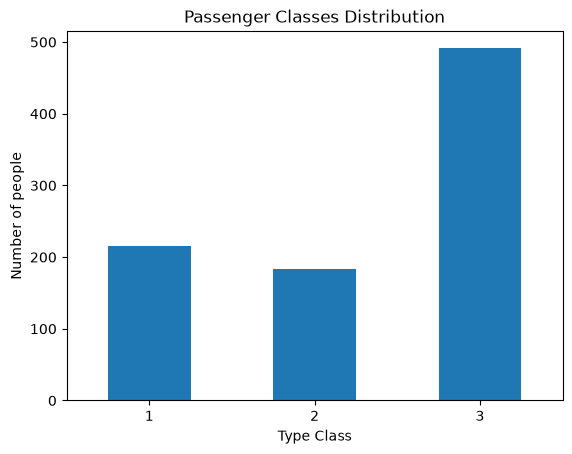

In [35]:
# Bar plot of Pclass
df_titanic['Pclass'].value_counts().sort_index().plot(
    kind='bar', 
    title= "Passenger Classes Distribution",
    ylabel="Number of people",
    xlabel="Type Class",
    rot = 0) 

<Axes: title={'center': 'Percentage of Survivors'}>

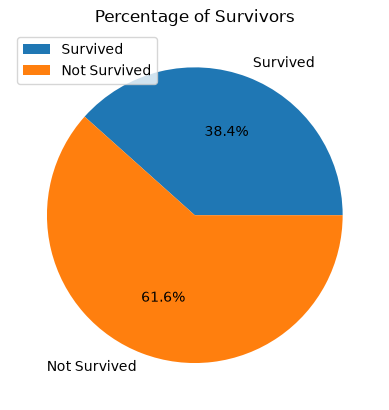

In [66]:
# My way 
survived_per = (len(df_titanic[df_titanic["Survived"] == 1]) * 100 / len(df_titanic))
not_survived = 100 - survived_per

# Wrap the values in lists so pandas knows they are rows/columns
titanic_survivors = {
    "Status": ["Survived", "Not Survived"],
    "Percentage": [survived_per, not_survived]
}

df_titanic_survivors = pd.DataFrame(titanic_survivors)

# Set 'Status' as the index, just like you set 'Month' in your sales example
df_titanic_survivors = df_titanic_survivors.set_index('Status')

# Pie Chart Survived/not
df_titanic_survivors.plot(
    kind="pie",
    y="Percentage", # Just like specifying y='Product_A_Sales' in class!
    autopct="%1.1f%%",
    title='Percentage of Survivors',
    ylabel='' # Cleans up the axis label on the side
)

<Axes: title={'center': 'Percentage of Survivors vs. Not Survived'}>

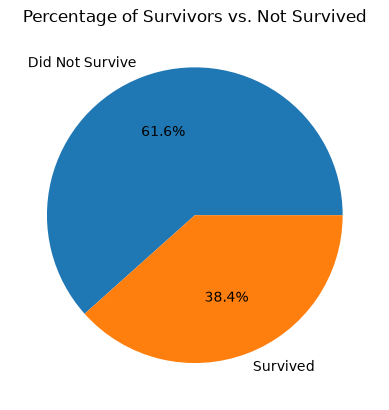

In [ ]:
# The gemini way
df_titanic['Survived'].value_counts().rename({0: 'Did Not Survive', 1: 'Survived'}).plot(
    kind='pie',
    autopct='%1.1f%%',
    title='Percentage of Survivors vs. Not Survived',
    ylabel='' # Removes the default column name label on the side
)

<Axes: title={'center': 'Age Distribution'}, xlabel='Passenger Age', ylabel='Number of Passengers'>

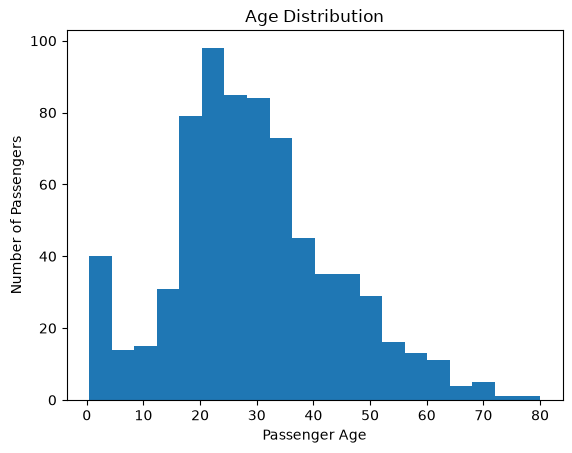

In [77]:
# Histogram of age distribution. 
df_titanic['Age'].plot(
    kind = 'hist',
    title = 'Age Distribution',
    xlabel = 'Passenger Age',
    ylabel = 'Number of Passengers',
    bins = 20
)

In [ ]:
# Create a helping function because i can't make it with lambda. 
def age_group(age: int) -> str :
    """Give the age group accord the age of people."""
    if pd.isna(age):
        return 'Unknown'
    elif age < 18 :
        return 'Child'
    elif 18 <= age < 60:
        return 'Adult'
    else:
        return 'Senior'
    

# Create age group column.
df_titanic['Age_Group'] = df_titanic['Age'].apply(age_group)



In [124]:
def family_size(row)-> int :
    """This function add all the family members """
    return row['SibSp'] + row['Parch'] + 1

#Create a Family Size column
df_titanic['Family_Size'] = df_titanic.apply(family_size, axis=1)
df_titanic.head()



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_Group,Family_Size
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Adult,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Adult,2
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Adult,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Adult,2
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Adult,1


In [125]:
# Challenge
grouped_family_size_df =  df_titanic.groupby('Family_Size')['Survived'].mean()


In [130]:
print(f"The Average Survival rate for passengers based on their family size is:\n {grouped_family_size_df}")

The Average Survival rate for passengers based on their family size is:
 Family_Size
1     0.303538
2     0.552795
3     0.578431
4     0.724138
5     0.200000
6     0.136364
7     0.333333
8     0.000000
11    0.000000
Name: Survived, dtype: float64


<Axes: title={'center': 'Average Survival rate per family size'}, xlabel='Family Size', ylabel='Survival rate'>

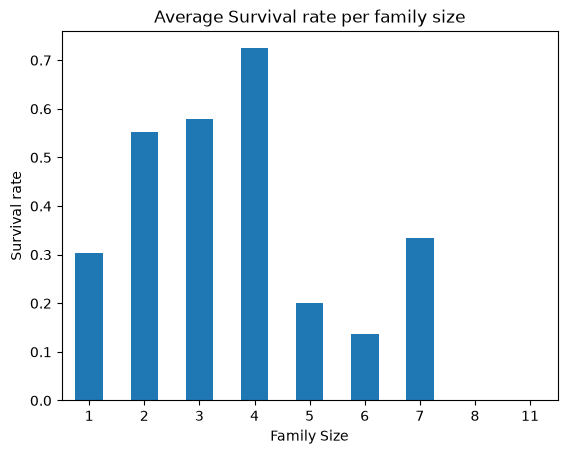

In [132]:
# The bar plot 
grouped_family_size_df.sort_index().plot(
    kind='bar', 
    title= "Average Survival rate per family size",
    ylabel="Survival rate",
    xlabel="Family Size",
    rot = 0,
) 
